# 22 · Supersampling a fit with long exposures

**Level:** intermediate · **Prerequisites:** [11](11_your_first_fit_with_is.ipynb) (and [04](04_observing_realities.ipynb) for the light-curve side) · **Run time:** ~1 min

**Covers:** why a long exposure smears a transit, what happens to the posterior if the fit ignores it, `supersample_factor`
and `exp_time` in `MarginalTransitModel`, midpoint sub-exposures, and a quick check of how many sub-exposures a light
curve needs.

A Kepler long-cadence point is not a snapshot: the camera adds up the light of the star for 29.4 minutes and records the
average. The ingress and egress of a transit last only minutes, so the recorded light curve is a smeared version of the
true one: the dip looks shallower at its edges and its corners are rounded. A model that is evaluated only at the middle
of each exposure has sharp corners, and the fit then bends the planet's parameters until the sharp model looks like the
smeared data.

pizzetti's `MarginalTransitModel` does not supersample by default (`supersample_factor=1`). In this tutorial we fit the
same Kepler light curve of TrES-2 b (Kepler-1 b) twice, once with that default and once with the exposure averaged over
sub-exposures, and compare the two results.

In [1]:
import os
import warnings
from time import perf_counter
import numpy as np
import matplotlib.pyplot as plt
with warnings.catch_warnings():
    warnings.simplefilter("ignore", UserWarning)        # lightkurve warns about an optional package
    import lightkurve as lk
from wotan import flatten, transit_mask
import corner
import pizzetti

# the two fits are saved here after the first run, so that re-running the notebook is quick; delete the file to refit
CACHE = os.path.expanduser("~/.cache/pizzetti-tutorials/22_long_exposures.npz")
print("pizzetti", pizzetti.__version__)

pizzetti 0.5.0


## Step 1: the light curve

One quarter (Q3) of Kepler long-cadence data of TrES-2 b: a hot Jupiter on a 2.47-day orbit with a high impact
parameter, so its ingress and egress are long and the shape of the dip carries much of the information on b and a/R★.
We take the exposure time from the time stamps: Kepler long cadence is 1765.5 s, not the nominal 1800 s.

In [2]:
with warnings.catch_warnings():
    warnings.simplefilter("ignore", UserWarning)
    lc = lk.search_lightcurve("Kepler-1", mission="Kepler", author="Kepler", exptime=1800, quarter=3).download()
lc = lc.remove_nans().normalize()
time_all, flux_all = lc.time.value, lc.flux.value       # BKJD = BJD - 2454833
exposure = float(np.median(np.diff(time_all)))          # days
print(f"{len(time_all)} points, exposure {exposure * 86400:.1f} s = {exposure * 24 * 60:.1f} min")

period = 2.47063                 # days
t0 = 2454955.76336 - 2454833     # a mid-transit time (BKJD)
t14 = 0.0726                     # transit duration (days), about 1.7 h

4134 points, exposure 1765.4 s = 29.4 min


## Step 2: detrend and keep the data around the transits

As in tutorial 11: a biweight filter (wotan) with the transits masked, then only the points within 1.5 transit durations
of mid-transit. The noise per point comes from the scatter out of transit.

350 points near 33 transits, noise 54 ppm per point


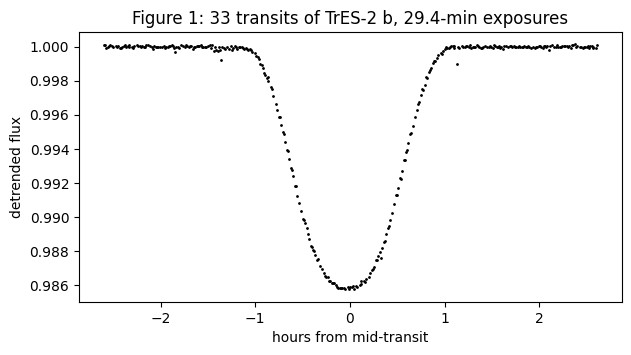

In [3]:
mask = transit_mask(time=time_all, period=period, duration=1.1 * t14 + exposure, T0=t0)
flat = flatten(time_all, flux_all, method="biweight", window_length=2.0, mask=mask)
ok = np.isfinite(flat)
phase = (time_all[ok] - t0 + 0.5 * period) % period - 0.5 * period      # days from mid-transit
near = np.abs(phase) < 1.5 * t14
time, flux, phase = time_all[ok][near], flat[ok][near], phase[near]
out = np.abs(phase) > 0.5 * t14 + exposure
sigma = 1.4826 * np.median(np.abs(flux[out] - np.median(flux[out])))
print(f"{len(time)} points near {len(np.unique(np.round((time - t0) / period)))} transits, noise {sigma * 1e6:.0f} ppm per point")

plt.figure(figsize=(7, 3.5))
plt.plot(24 * phase, flux, "k.", ms=2)
plt.xlabel("hours from mid-transit"); plt.ylabel("detrended flux")
plt.title("Figure 1: 33 transits of TrES-2 b, 29.4-min exposures");

## Step 3: how many sub-exposures?

With supersampling, the model is computed at `k` times inside each exposure and averaged. pizzetti places them at the
midpoints of `k` equal parts of the exposure (`offsets="midpoint"`, the default of `MarginalTransitModel`), whose error
falls as 1/k².

How large must `k` be? The error that matters is not the error of one point but its effect on the fit, summed over all
points: χ² = Σ (f_k − f_exact)² / σ², with f_exact computed from many sub-exposures. If it is far below 1, the
posterior cannot move by more than about √χ² standard deviations (in practice usually much less).
`pizzetti.choose_supersample` computes it at given parameters, here the catalogue values before any fit, and returns
the smallest `k` with χ² ≤ 0.01 (a shift of at most 0.1 σ). `pizzetti.exposure_chi2` gives the χ² for any `k`.

k =   1: chi2 of the model error  1.721e+04
k =   2: chi2 of the model error      752.8
k =   3: chi2 of the model error        141
k =   4: chi2 of the model error      43.17
k =   5: chi2 of the model error      16.85
k =   6: chi2 of the model error      7.986
k =   8: chi2 of the model error      2.474
k =  10: chi2 of the model error     0.9834
k =  12: chi2 of the model error     0.4665
k =  15: chi2 of the model error     0.1794
k =  18: chi2 of the model error    0.08633
k =  21: chi2 of the model error    0.04664
k =  25: chi2 of the model error    0.02342
k =  31: chi2 of the model error   0.009743
-> k = 31


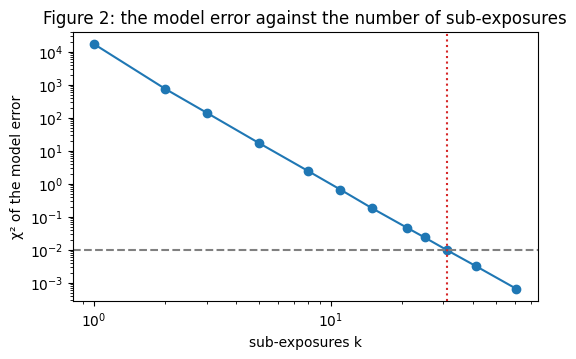

In [4]:
params = pizzetti.TransitParams()
params.t0, params.per, params.rp, params.a = t0, period, 0.1254, 7.64       # catalogue values as a first guess
params.inc = np.degrees(np.arccos(0.843 / 7.64))
params.ecc, params.w, params.limb_dark, params.u = 0.0, 90.0, "quadratic", [0.4, 0.25]

k_fit, table = pizzetti.choose_supersample(params, time, exposure, sigma, return_table=True)
for k, c in table.items():
    print(f"k = {k:3d}: chi2 of the model error {c:10.4g}")
print(f"-> k = {k_fit}")

ks = np.array([1, 2, 3, 5, 8, 11, 15, 21, 25, 31, 41, 61])
chi2 = np.array([pizzetti.exposure_chi2(params, time, exposure, sigma, k) for k in ks])

plt.figure(figsize=(6, 3.5))
plt.loglog(ks, chi2, "o-")
plt.axhline(0.01, color="0.5", ls="--"); plt.axvline(k_fit, color="C3", ls=":")
plt.xlabel("sub-exposures k"); plt.ylabel("χ² of the model error")
plt.title("Figure 2: the model error against the number of sub-exposures");

Without supersampling (k = 1) the model is off by a χ² of about 17 000: the fit will have to compensate. The error then
falls as 1/k⁴ (1/k² per point, squared). A common rule of thumb, one sub-exposure per 2 minutes of exposure (k = 15 here),
still leaves χ² ≈ 0.2 for these 350 precise points, enough to move the posterior by up to about 0.4 σ. This light curve
needs 31.

## Step 4: two fits

Fit A is the default: no supersampling, the model evaluated at the middle of each exposure. Fit B averages the model over
`k_fit` midpoint sub-exposures of the measured exposure time; `supersample_factor="auto"` with `exp_time` does the same
in one step (it calls `choose_supersample` at `params`). Everything else is the same: free t0, Rp/R★, a/R★ and b, the
limb darkening and the baseline integrated out (tutorial 11), and an upper bound on Rp/R★ (a high-b transit can
otherwise extend along a grazing ridge without limit).

After a fit, `fit()` checks the exposure average once more at the posterior median and reports the χ² in
`diagnostics["supersample_chi2"]`. Without supersampling and without `exp_time`, as in fit A, it assumes that each point
is an exposure as long as the cadence (as for Kepler and TESS) and warns if the posterior could move by more than about
0.3 σ. The cell saves both fits, with any warning, so that they are not repeated when the notebook runs again.

In [5]:
def fit(k):
    if k == 1:          # fit A: pizzetti's default, no exposure average and no exposure time given
        model = pizzetti.MarginalTransitModel(params, time, flux, sigma, free=["t0", "rp", "a", "b"],
                                              bounds={"rp": (1e-4, 0.5)})
    else:               # fit B
        model = pizzetti.MarginalTransitModel(params, time, flux, sigma, free=["t0", "rp", "a", "b"],
                                              bounds={"rp": (1e-4, 0.5)}, supersample_factor=k, exp_time=exposure)
    t_start = perf_counter()
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always")
        result = model.fit(ld="u", seed=1)
    wall = perf_counter() - t_start
    d = result.diagnostics
    return dict(samples=result.samples, labels=np.array(result.labels), wall=wall, n_eval=d["n_eval"], ess=d["ess_total"],
                khat=d["khat"], is_ok=d["is_ok"], chi2=d.get("supersample_chi2"),
                warnings=[str(c.message) for c in caught if issubclass(c.category, UserWarning)])

if os.path.exists(CACHE):
    z = np.load(CACHE, allow_pickle=True)
    fits = z["fits"].item()
    print("loaded the saved fits from", CACHE)
else:
    fits = {"A": fit(1), "B": fit(k_fit)}
    fits["B"]["k"], fits["A"]["k"] = k_fit, 1
    os.makedirs(os.path.dirname(CACHE), exist_ok=True)
    np.savez(CACHE, fits=np.array(fits, dtype=object))
for key, name in (("A", "without supersampling"), ("B", f"with {fits['B']['k']} sub-exposures")):
    f = fits[key]
    print(f"fit {key} ({name}): {f['wall']:.1f} s, {f['n_eval']} likelihood evaluations, ESS {f['ess']:.0f}, "
          f"k-hat {f['khat']:.2f}, passes its checks: {f['is_ok']}, exposure-average chi2 {f['chi2']:.3g}")
    for w in f["warnings"]:
        print("    warning:", w)

loaded the saved fits from /home/michael/.cache/pizzetti-tutorials/22_long_exposures.npz
fit A (without supersampling): 0.4 s, 9434 likelihood evaluations, ESS 4101, k-hat -0.28, passes its checks: True, exposure-average chi2 2.21e+04
fit B (with 31 sub-exposures): 5.0 s, 30995 likelihood evaluations, ESS 4129, k-hat 0.06, passes its checks: True, exposure-average chi2 0.0103


Fit A's warning names 37 sub-exposures rather than 31 because it evaluates the error at fit A's own, biased posterior;
at fit B's posterior, 31 give χ² = 0.010.

## Step 5: the two posteriors

The table lists the median and the 1σ range of each parameter in both fits, and how far fit A's median lies from fit B's,
in units of fit B's standard deviation. T14, the total duration, is computed from the others.

In [6]:
def table_of(f):
    lab = list(f["labels"])
    S = {n: f["samples"][:, lab.index(n)] for n in ("rp", "a", "b", "u1", "u2")}
    S["b"] = np.abs(S["b"])
    S["T14 (h)"] = 24 * period / np.pi * np.arcsin(np.sqrt(np.clip((1 + S["rp"]) ** 2 - S["b"] ** 2, 0, None))
                                                   / np.sqrt(S["a"] ** 2 - S["b"] ** 2))
    S["depth (ppm)"] = 1e6 * S["rp"] ** 2
    return S

SA, SB = table_of(fits["A"]), table_of(fits["B"])
print(f"{'':12s} {'fit A: no supersampling':>26s} {'fit B: k = ' + str(fits['B']['k']):>26s} {'A - B':>10s}")
for n in SB:
    qa, qb = np.percentile(SA[n], [16, 50, 84]), np.percentile(SB[n], [16, 50, 84])
    sd = 0.5 * (qb[2] - qb[0])
    print(f"{n:12s} {qa[1]:12.5g} +{qa[2] - qa[1]:.2g} -{qa[1] - qa[0]:.2g} {qb[1]:12.5g} +{qb[2] - qb[1]:.2g} -{qb[1] - qb[0]:.2g} "
          f"{(qa[1] - qb[1]) / sd:+8.1f} σ")

                fit A: no supersampling              fit B: k = 31      A - B
rp                  0.138 +0.00057 -0.00041      0.12522 +0.0025 -0.0015     +6.4 σ
a                  7.2737 +0.024 -0.018       7.9108 +0.11 -0.095     -6.1 σ
b                 0.80946 +0.0027 -0.0026      0.84405 +0.0098 -0.012     -3.2 σ
u1                 1.6442 +0.027 -0.028      0.38299 +0.36 -0.27     +4.0 σ
u2               -0.65623 +0.032 -0.037      0.20429 +0.33 -0.39     -2.4 σ
T14 (h)            2.0935 +0.0065 -0.0094       1.7877 +0.016 -0.011    +22.8 σ
depth (ppm)         19044 +1.6e+02 -1.1e+02        15681 +6.2e+02 -3.8e+02     +6.7 σ


Without supersampling the fit makes the transit longer (T14 2.09 h instead of 1.79 h, 22 σ) and deeper (Rp/R★
0.138 instead of 0.125), with a smaller a/R★ and b, and it pushes the limb darkening to an extreme (u1 ≈ 1.6,
u2 ≈ −0.7) to round off the bottom of its sharp model. Its error bars are also about four times narrower than those of
fit B: the result is precise, and wrong, because the error bars do not include the model error.

## Step 6: what the two models look like on the data

By eye, both best fits follow the data. The residuals, binned to 10 minutes, show the difference: fit A swings by about
±150 ppm through the transit, because a sharp model cannot take the shape of a smeared dip, while fit B stays within
the noise (the two low bins outside the transit are shared by both fits: a few outlying points).

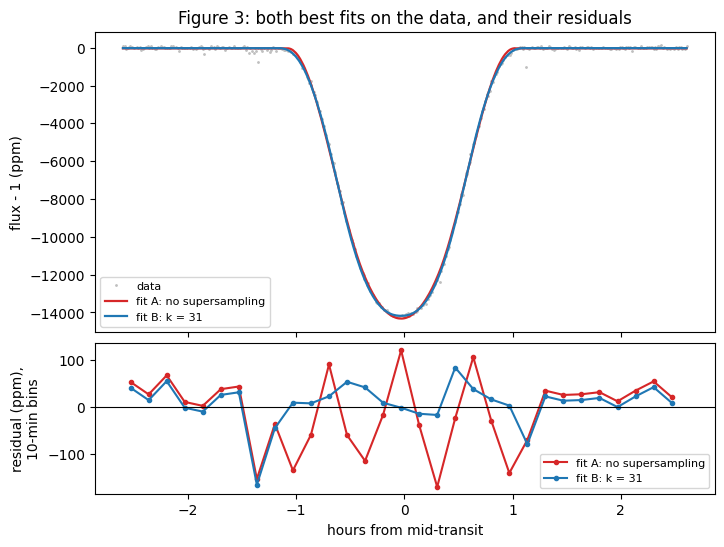

In [7]:
def best_model(f, k, t):
    lab = list(f["labels"])
    med = dict(zip(lab, np.median(f["samples"], axis=0)))
    p = pizzetti.TransitParams()
    p.t0, p.per, p.rp, p.a = med["t0"], period, med["rp"], med["a"]
    p.inc = np.degrees(np.arccos(abs(med["b"]) / med["a"]))
    p.ecc, p.w, p.limb_dark, p.u = 0.0, 90.0, "quadratic", [med["u1"], med["u2"]]
    m = pizzetti.TransitModel(p, t, supersample_factor=k, exp_time=exposure if k > 1 else 0.0, offsets="midpoint")
    return med["f0"] * m.light_curve(p), med["t0"]

edges = np.arange(-1.5 * t14, 1.5 * t14 + 1e-9, 10 / 1440)
fig, ax = plt.subplots(2, 1, figsize=(8, 6), sharex=True, gridspec_kw=dict(height_ratios=(2, 1), hspace=0.05))
ax[0].plot(24 * phase, 1e6 * (flux - 1), ".", color="0.75", ms=2, label="data")
for key, col, name in (("A", "C3", "fit A: no supersampling"), ("B", "C0", f"fit B: k = {fits['B']['k']}")):
    k = fits[key]["k"]
    model, tm = best_model(fits[key], k, time)
    o = np.argsort(phase)
    ax[0].plot(24 * phase[o], 1e6 * (model[o] - 1), color=col, lw=1.6, label=name)
    idx = np.digitize(phase, edges)
    r = np.array([np.mean((flux - model)[idx == i]) if np.any(idx == i) else np.nan for i in range(1, len(edges))])
    ax[1].plot(24 * 0.5 * (edges[1:] + edges[:-1]), 1e6 * r, "o-", color=col, ms=3, label=name)
ax[1].axhline(0, color="k", lw=0.8)
ax[0].set_ylabel("flux - 1 (ppm)"); ax[1].set_ylabel("residual (ppm),\n10-min bins")
ax[1].set_xlabel("hours from mid-transit"); ax[0].legend(fontsize=8); ax[1].legend(fontsize=8)
ax[0].set_title("Figure 3: both best fits on the data, and their residuals");

## Step 7: the posteriors side by side

The corner plot overlays both posteriors. They do not overlap: neither the statistical uncertainty nor the limb
darkening, which is fully marginalised in both fits, can make up for the missing exposure average.

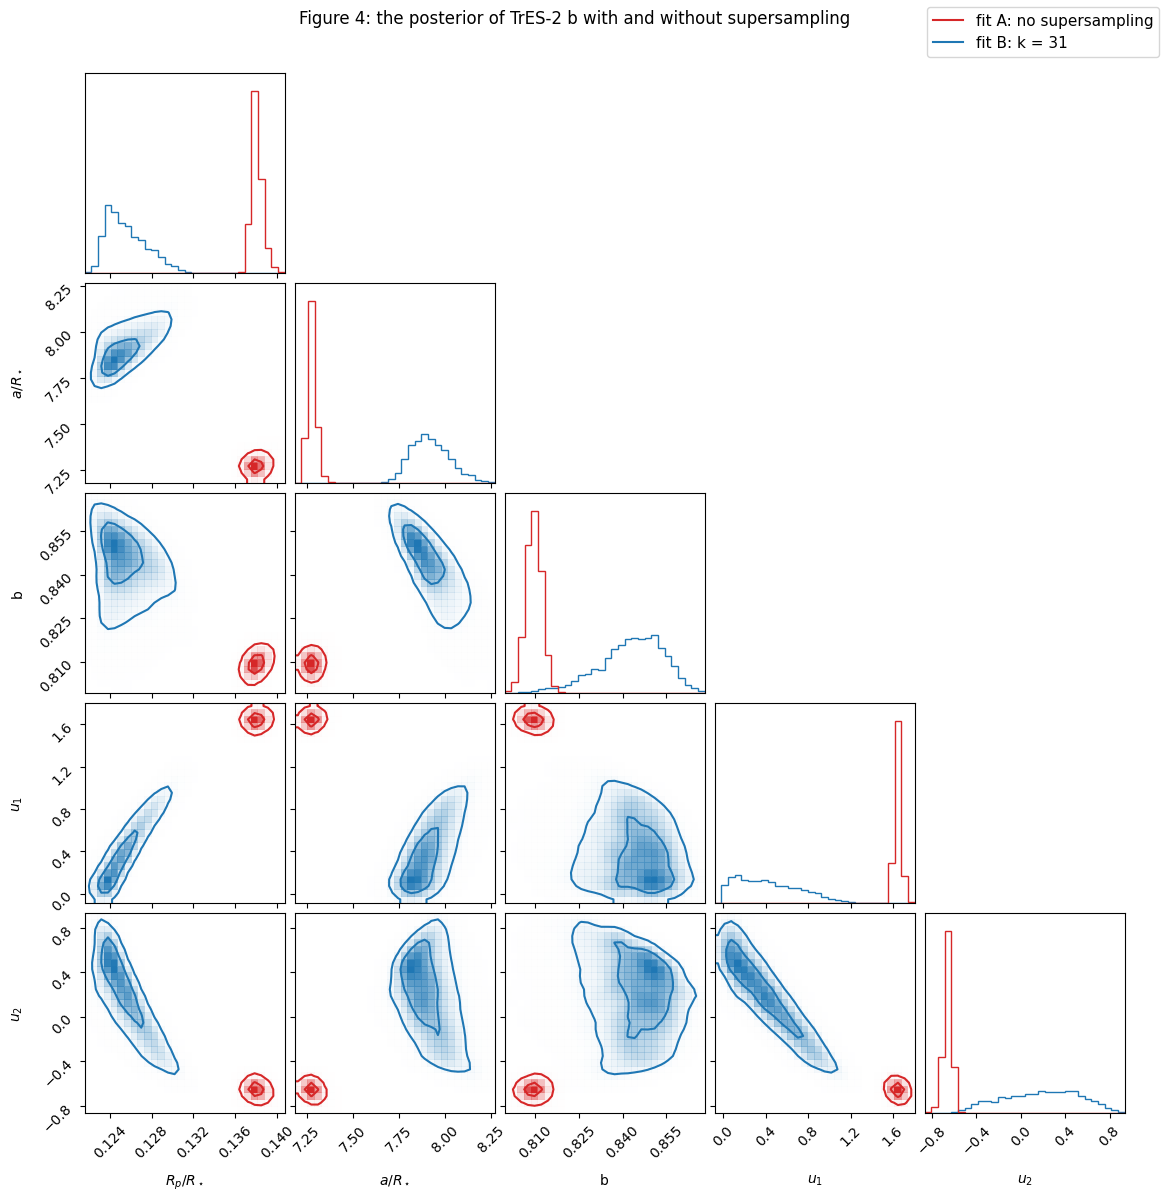

In [8]:
names = ["rp", "a", "b", "u1", "u2"]
XA = np.column_stack([np.abs(SA[n]) if n == "b" else SA[n] for n in names])
XB = np.column_stack([np.abs(SB[n]) if n == "b" else SB[n] for n in names])
lo = np.minimum(np.percentile(XA, 0.5, axis=0), np.percentile(XB, 0.5, axis=0))
hi = np.maximum(np.percentile(XA, 99.5, axis=0), np.percentile(XB, 99.5, axis=0))
rng = list(zip(lo - 0.05 * (hi - lo), hi + 0.05 * (hi - lo)))
fig = corner.corner(XB, labels=[r"$R_p/R_\star$", r"$a/R_\star$", "b", "$u_1$", "$u_2$"], range=rng, color="C0",
                    plot_datapoints=False, smooth=1.0, levels=(0.39, 0.86), bins=30)
corner.corner(XA, range=rng, color="C3", fig=fig, plot_datapoints=False, smooth=1.0, levels=(0.39, 0.86), bins=30)
fig.legend(handles=[plt.Line2D([], [], color="C3", label="fit A: no supersampling"),
                    plt.Line2D([], [], color="C0", label=f"fit B: k = {fits['B']['k']}")], loc="upper right", fontsize=11)
fig.suptitle("Figure 4: the posterior of TrES-2 b with and without supersampling", y=1.02);

## Step 8: the cost

Supersampling multiplies the number of model points by `k`, so each likelihood evaluation costs more. For a few hundred
points the fit still takes seconds.

In [9]:
for key in ("A", "B"):
    f = fits[key]
    print(f"fit {key}: k = {f['k']:2d}, {len(time) * f['k']:6d} model points, {f['n_eval']:6d} evaluations, {f['wall']:5.1f} s")

fit A: k =  1,    350 model points,   9434 evaluations,   0.4 s
fit B: k = 31,  10850 model points,  30995 evaluations,   5.0 s


## What you learned

- A long exposure averages the light curve. Ignoring it does not make the fit fail: it gives a precise posterior in the
  wrong place (here a longer, deeper transit, a smaller a/R★ and b, and extreme limb darkening; T14 off by 22 σ).
- `pizzetti.choose_supersample(params, t, exp_time, sigma)` returns the smallest `k` whose model error is χ² ≤ 0.01;
  `supersample_factor="auto"` uses it directly, and `fit()` checks the result again at the posterior median
  (`diagnostics["supersample_chi2"]`), also when no exposure time is given (then it assumes the cadence).
- `MarginalTransitModel(..., supersample_factor=k, exp_time=...)` averages the model over `k` sub-exposures, placed at the
  midpoints of equal sub-intervals by default (`offsets="midpoint"`; `"batman"` places them from edge to edge, as batman,
  and is much less accurate at the same `k`).
- How many: compute χ² of the model error against a finely supersampled model, summed over your points, and take the
  smallest `k` with χ² ≪ 1 (0.01 bounds the shift at about 0.1 σ). The answer depends on the light curve: a deep,
  precise transit with long ingresses needs many; a shallow, noisy one may need few. A fixed rule such as one
  sub-exposure per 2 minutes can be too few for a long, precise light curve.
- For exposures of 2 minutes or less (TESS 2-min, Kepler short cadence), the smearing is usually negligible: check with
  the same χ².

**Next:** [04](04_observing_realities.ipynb) shows long exposures on the light-curve side (`TransitModel`);
[17](17_the_grand_tour.ipynb) runs the whole chain from download to posterior.